# Chartist: nuestro modelo frente al paper

Reproducción de la Tabla 1 de Shi et al., *Chartist: Task-driven Eye Movement Control for Chart Reading*
(CHI 2025, [arXiv 2502.03575](https://arxiv.org/abs/2502.03575)).

- **Modelo:** `models.chartist.Chartist`. Ejecuta sin cambios `LLMPolicy` y las cuatro políticas PPO oficiales.
- **Datos:** 12 condiciones de TaskVis (4 gráficos de barras × 3 tareas) y 183 recorridos humanos.
  Los gráficos y metadatos son los oficiales, en `official_reference/`.
- **Protocolo:** un recorrido nuestro por cada recorrido humano de la condición (14–16), igual que en el paper.
  Las métricas se calculan en píxeles de la imagen original.

Kernel: **Python 3.8 (GazePrediction)**.

In [19]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'models/__init__.py').is_file())
sys.path.insert(0, str(ROOT))
from reproductions.chartist_taskvis.metrics import METRICS, evaluate, load_aois

EXPERIMENT = ROOT / 'reproductions/chartist_taskvis'
OFFICIAL = EXPERIMENT / 'official_reference'
DATA = EXPERIMENT / 'data'
PREDICTIONS = EXPERIMENT / 'results/predictions'
LOGS = PREDICTIONS.parent / 'logs'

TASKS = ['retrieve_value', 'filter', 'find_extreme']
TASK_CODE = {'retrieve_value': 'RV', 'filter': 'F', 'find_extreme': 'FE'}

cases = pd.read_csv(DATA / 'cases.csv')
human_fixations = pd.read_csv(DATA / 'human_fixations.csv')
display(cases)

,id,image,task,question,width,height,n_humans
0,1,economist_daily_chart_35,retrieve_value,How many paralympic competitors per million population does France have?,1000,973,15
1,6,economist_daily_chart_35,filter,Which countries have more than 10 paralympic competitors per million population?,1000,973,15
2,9,economist_daily_chart_35,find_extreme,Which country has most paralympic competitors per million population?,1000,973,15
3,11,economist_daily_chart_85,retrieve_value,What is the attendance of Universal Studios Hollywood?,1000,980,15
4,16,economist_daily_chart_85,filter,Which theme parks had more than 15 million attendance in 2011?,1000,980,16
5,19,economist_daily_chart_85,find_extreme,Which theme park had the highest attendance in 2011?,1000,980,15
6,21,economist_daily_chart_165,retrieve_value,How many deceased organ donors per million population does Brazil have?,1000,919,16
7,25,economist_daily_chart_165,filter,Which country has 25 of deceased organ donors per million population?,1000,919,15
8,30,economist_daily_chart_165,find_extreme,Which country has the lowest number of living organ donors per million population?,1000,919,16
9,31,economist_daily_chart_392,retrieve_value,What was the earthquake magnitude in Kamchatka in 1952?,1000,798,16


## 1. Entrada del modelo

`Chartist.predict(meta, meta_json=..., folder=...)` recibe dos cosas:

- **`meta`:** un registro de `meta.json` con la pregunta, el tipo de gráfico y el texto OCR con sus cajas.
- **`folder`:** la carpeta `images/` con las entradas visuales ya preparadas de esa condición (`chart_<id>_*.png`).

Los autores entregan todo esto ya generado por `data_gen.py` para las 40 condiciones, así que **no procesamos nada**.
La tabla indica qué archivo lee cada parte del controlador y **cómo lo usa al predecir**:

| Entrada | Origen (`data_gen.py`) | Tamaño | Uso al predecir |
|---|---|---|---|
| `question` | TaskVis | texto | prompt del LLM y *embedding* `stsb-roberta-base-v2` (observación de search y read) |
| `text_positions` | PaddleOCR + similitud con la pregunta | cajas en 320 × 320 | texto bajo la mirada, que pasa a la memoria del LLM |
| `chart_N.png` | gráfico redimensionado | 320 × 320 | imagen base del entorno |
| `chart_N_p.png` | gráfico reducido (visión periférica) | 20 × 20 | **observación PPO** (los cuatro entornos) |
| `chart_N_saliency.png` | VisSalFormer con la pregunta | 20 × 20 | **observación PPO** (search, map, read) |
| `chart_N_semantic.png` | similitud OCR–pregunta, solo en ejes | 20 × 20 | **observación PPO** de search, limitada a celdas visitadas |
| `chart_N_mark.png` | rótulo manual `mark` | 20 × 20 | map: añade "gaze is on the mark" a la memoria |
| `chart_N_search.png` | rótulo manual de tarea | 20 × 20 | map: **celda inicial de la mirada**, elegida al azar dentro de esta zona |
| `chart_N_map_mark.png` | rótulo manual de tarea | 20 × 20 | read: **celda inicial de la mirada**, elegida al azar dentro de esta zona |
| `chart_N_title.png`, `_axis`, `_map`, `_read` | rótulos manuales | 20 × 20 | solo recompensa (entrenamiento); no cambian las acciones |

Las observaciones también incluyen la fijación actual, las celdas visitadas y, en map/read, la celda de referencia
que pidió el LLM. Ojo con los rótulos de tarea: aunque sean anotaciones manuales, `search` y `map_mark`
deciden dónde empiezan `look_at_data_point` y `read_axis` (`map_env.init()` y `read_env.init()`).
Así funciona el código oficial y lo conservamos tal cual; para gráficos nuevos habría que anotarlos a mano.

In [20]:
EXAMPLE_ID = 1   # cualquier id de cases.csv
IMAGES = OFFICIAL / 'images'
meta_by_id = {m['id']: m for m in json.loads((OFFICIAL / 'meta.json').read_text())}
example = meta_by_id[EXAMPLE_ID]

# Registro tal como está en meta.json (text_positions recortado a 2 elementos)
print(json.dumps({**example, 'text_positions': example['text_positions'][:2] + ['...']}, indent=2, ensure_ascii=False))

{
  "id": 1,
  "image": "economist_daily_chart_35",
  "task": "retrieve_value",
  "chart_type": "a horizontal bar chart",
  "question": "How many paralympic competitors per million population does France have?",
  "text_positions": [
    {
      "position": [
        10,
        7,
        141,
        16
      ],
      "text": "Paralympic and Olympic competitors",
      "ocr_score": 0.9772529602050781,
      "semantic_similarity": 0.5112895965576172
    },
    {
      "position": [
        11,
        19,
        128,
        26
      ],
      "text": "Per million population, summer 2012 games",
      "ocr_score": 0.9649481177330017,
      "semantic_similarity": 0.38961637020111084
    },
    "..."
  ]
}


### Qué entra al modelo en una condición

Para predecir un recorrido de la condición `EXAMPLE_ID`, el modelo recibe su registro de `meta.json` (A)
y lee sus 12 imágenes `images/chart_<id>_*.png` (B). Las tablas indican el tipo y el contenido de cada entrada,
y si el código oficial la usa al predecir. En `meta`, el código solo lee `id`, `question` y `text_positions`
(de este último, solo `position` y `text`).

In [21]:
META_FIELDS = {  # campo: (tipo, uso al predecir)
    'id': ('int', 'Forma los nombres de archivo chart_{id}_*.png'),
    'image': ('str', 'No se usa al predecir (nombre del gráfico en TaskVis)'),
    'task': ('str', 'No se usa al predecir (retrieve_value / filter / find_extreme)'),
    'chart_type': ('str', 'No se usa: el prompt siempre dice "a scatterplot"'),
    'question': ('str', 'Prompt del LLM y embedding stsb-roberta-base-v2 (search y read)'),
    'text_positions': ('list[dict]', 'Texto de las cajas bajo la mirada, a la memoria del LLM'),
}
TEXT_FIELDS = {  # campo de cada caja: (tipo, contenido, uso al predecir)
    'position': ('list[int] (4)', '[left, top, right, bottom] en píxeles de 320 × 320', 'Sí: cruce con la zona de la mirada'),
    'text': ('str', 'Texto reconocido por PaddleOCR', 'Sí: pasa a la memoria del LLM'),
    'ocr_score': ('float', 'Confianza de PaddleOCR (0–1)', 'No'),
    'semantic_similarity': ('float', 'Similitud coseno texto–pregunta (stsb-roberta, 0–1)', 'No (ya está en chart_N_semantic.png)'),
}
INPUT_FILES = [  # sufijo, contenido, uso al predecir
    ('', 'Gráfico redimensionado', 'Imagen base del entorno'),
    ('_p', 'Visión periférica (gráfico reducido)', 'Observación PPO (los cuatro entornos)'),
    ('_saliency', 'Saliencia de VisSalFormer con la pregunta', 'Observación PPO (search, map, read)'),
    ('_semantic', 'Similitud OCR–pregunta en zonas de ejes', 'Observación PPO (search)'),
    ('_search', 'Zona de búsqueda de la tarea (manual)', 'Inicio de la mirada en look_at_data_point'),
    ('_map_mark', 'Marca objetivo de la tarea (manual)', 'Inicio de la mirada en read_axis'),
    ('_mark', 'Marcas del gráfico (manual)', 'Texto "gaze is on the mark" para el LLM'),
    ('_title', 'Título (manual)', 'Solo recompensa'),
    ('_axis', 'Ejes (manual)', 'Solo recompensa'),
    ('_map', 'Extremo de la marca objetivo (manual)', 'Solo recompensa'),
    ('_read', 'Zona de lectura en el eje (manual)', 'Solo recompensa'),
    ('_origin', 'Gráfico original', 'No lo leen los entornos; da el tamaño para reescalar'),
]


def describe_image(path):
    image = Image.open(path)
    values = np.asarray(image)
    kind = f"PNG {image.mode} {image.width}×{image.height}, uint8 [{values.min()}–{values.max()}]"
    active = int((np.asarray(image.convert('L')) > 0).sum()) if image.size == (20, 20) else None
    return kind, active


def model_inputs(case_id):
    meta = meta_by_id[case_id]
    fields = pd.DataFrame([dict(Campo=name, Tipo=kind, Contenido=(f"{len(meta[name])} cajas OCR (tabla siguiente)"
                                if name == 'text_positions' else meta[name]), Uso=use)
                           for name, (kind, use) in META_FIELDS.items()])
    files = []
    for suffix, content, use in INPUT_FILES:
        path = IMAGES / f'chart_{case_id}{suffix}.png'
        kind, active = describe_image(path) if path.exists() else ('falta', None)
        files.append({'Archivo': path.name, 'Tipo': kind, 'Contenido': content, 'Uso': use, 'Celdas > 0': active})
    return fields, pd.DataFrame(files)


fields, files = model_inputs(EXAMPLE_ID)
print(f"Condición {EXAMPLE_ID}: {example['image']} · {example['task']}")
print('\nA. Registro de meta.json')
display(fields.style.hide(axis='index'))

print(f"A.1 Cada elemento de text_positions (dict)")
display(pd.DataFrame([dict(Campo=k, Tipo=t, Contenido=c, **{'¿Se usa?': u}) for k, (t, c, u) in TEXT_FIELDS.items()])
        .style.hide(axis='index'))

print(f"A.2 text_positions completo: {len(example['text_positions'])} cajas")
boxes = pd.DataFrame(example['text_positions'])
boxes[['left', 'top', 'right', 'bottom']] = pd.DataFrame(boxes.position.tolist(), index=boxes.index)
display(boxes[['text', 'left', 'top', 'right', 'bottom', 'ocr_score', 'semantic_similarity']]
        .style.format({'ocr_score': '{:.3f}', 'semantic_similarity': '{:.3f}'})
        .background_gradient(subset=['semantic_similarity'], cmap='viridis', vmin=0, vmax=1))

print('B. Imágenes de images/')
display(files.style.hide(axis='index').format({'Celdas > 0': lambda v: '' if pd.isna(v) else f'{v:.0f}'}))

Condición 1: economist_daily_chart_35 · retrieve_value

A. Registro de meta.json


Campo,Tipo,Contenido,Uso
id,int,1,Forma los nombres de archivo chart_{id}_*.png
image,str,economist_daily_chart_35,No se usa al predecir (nombre del gráfico en TaskVis)
task,str,retrieve_value,No se usa al predecir (retrieve_value / filter / find_extreme)
chart_type,str,a horizontal bar chart,"No se usa: el prompt siempre dice ""a scatterplot"""
question,str,How many paralympic competitors per million population does France have?,Prompt del LLM y embedding stsb-roberta-base-v2 (search y read)
text_positions,list[dict],70 cajas OCR (tabla siguiente),"Texto de las cajas bajo la mirada, a la memoria del LLM"


A.1 Cada elemento de text_positions (dict)


Campo,Tipo,Contenido,¿Se usa?
position,list[int] (4),"[left, top, right, bottom] en píxeles de 320 × 320",Sí: cruce con la zona de la mirada
text,str,Texto reconocido por PaddleOCR,Sí: pasa a la memoria del LLM
ocr_score,float,Confianza de PaddleOCR (0–1),No
semantic_similarity,float,"Similitud coseno texto–pregunta (stsb-roberta, 0–1)",No (ya está en chart_N_semantic.png)


A.2 text_positions completo: 70 cajas


,text,left,top,right,bottom,ocr_score,semantic_similarity
0,Paralympic and Olympic competitors,10,7,141,16,0.977,0.511
1,"Per million population, summer 2012 games",11,19,128,26,0.965,0.390
2,OParalympic competitors,156,19,225,26,0.991,0.425
3,Total Paralympic,262,19,306,26,0.998,0.444
4,(Paralympic rank out of163 countries),12,28,111,34,0.936,0.365
5,OOlympic competitors,156,28,217,35,0.977,0.351
6,competitors,268,27,300,33,0.999,0.301
7,0,63,45,67,50,0.795,0.009
8,5,92,44,97,51,0.999,0.000
9,10,120,44,129,51,0.998,0.000


B. Imágenes de images/


Archivo,Tipo,Contenido,Uso,Celdas > 0
chart_1.png,"PNG RGB 320×320, uint8 [0–255]",Gráfico redimensionado,Imagen base del entorno,
chart_1_p.png,"PNG RGB 20×20, uint8 [12–255]",Visión periférica (gráfico reducido),Observación PPO (los cuatro entornos),400
chart_1_saliency.png,"PNG L 20×20, uint8 [4–120]",Saliencia de VisSalFormer con la pregunta,"Observación PPO (search, map, read)",400
chart_1_semantic.png,"PNG L 20×20, uint8 [0–255]",Similitud OCR–pregunta en zonas de ejes,Observación PPO (search),16
chart_1_search.png,"PNG L 20×20, uint8 [0–255]",Zona de búsqueda de la tarea (manual),Inicio de la mirada en look_at_data_point,8
chart_1_map_mark.png,"PNG L 20×20, uint8 [0–255]",Marca objetivo de la tarea (manual),Inicio de la mirada en read_axis,6
chart_1_mark.png,"PNG L 20×20, uint8 [0–255]",Marcas del gráfico (manual),"Texto ""gaze is on the mark"" para el LLM",102
chart_1_title.png,"PNG L 20×20, uint8 [0–255]",Título (manual),Solo recompensa,26
chart_1_axis.png,"PNG L 20×20, uint8 [0–255]",Ejes (manual),Solo recompensa,78
chart_1_map.png,"PNG L 20×20, uint8 [0–255]",Extremo de la marca objetivo (manual),Solo recompensa,4


#### Las 12 imágenes tal como las lee el modelo

Sin superponer ni reescalar: los mapas de 20 × 20 se muestran píxel a píxel (cada píxel es una celda de la rejilla).

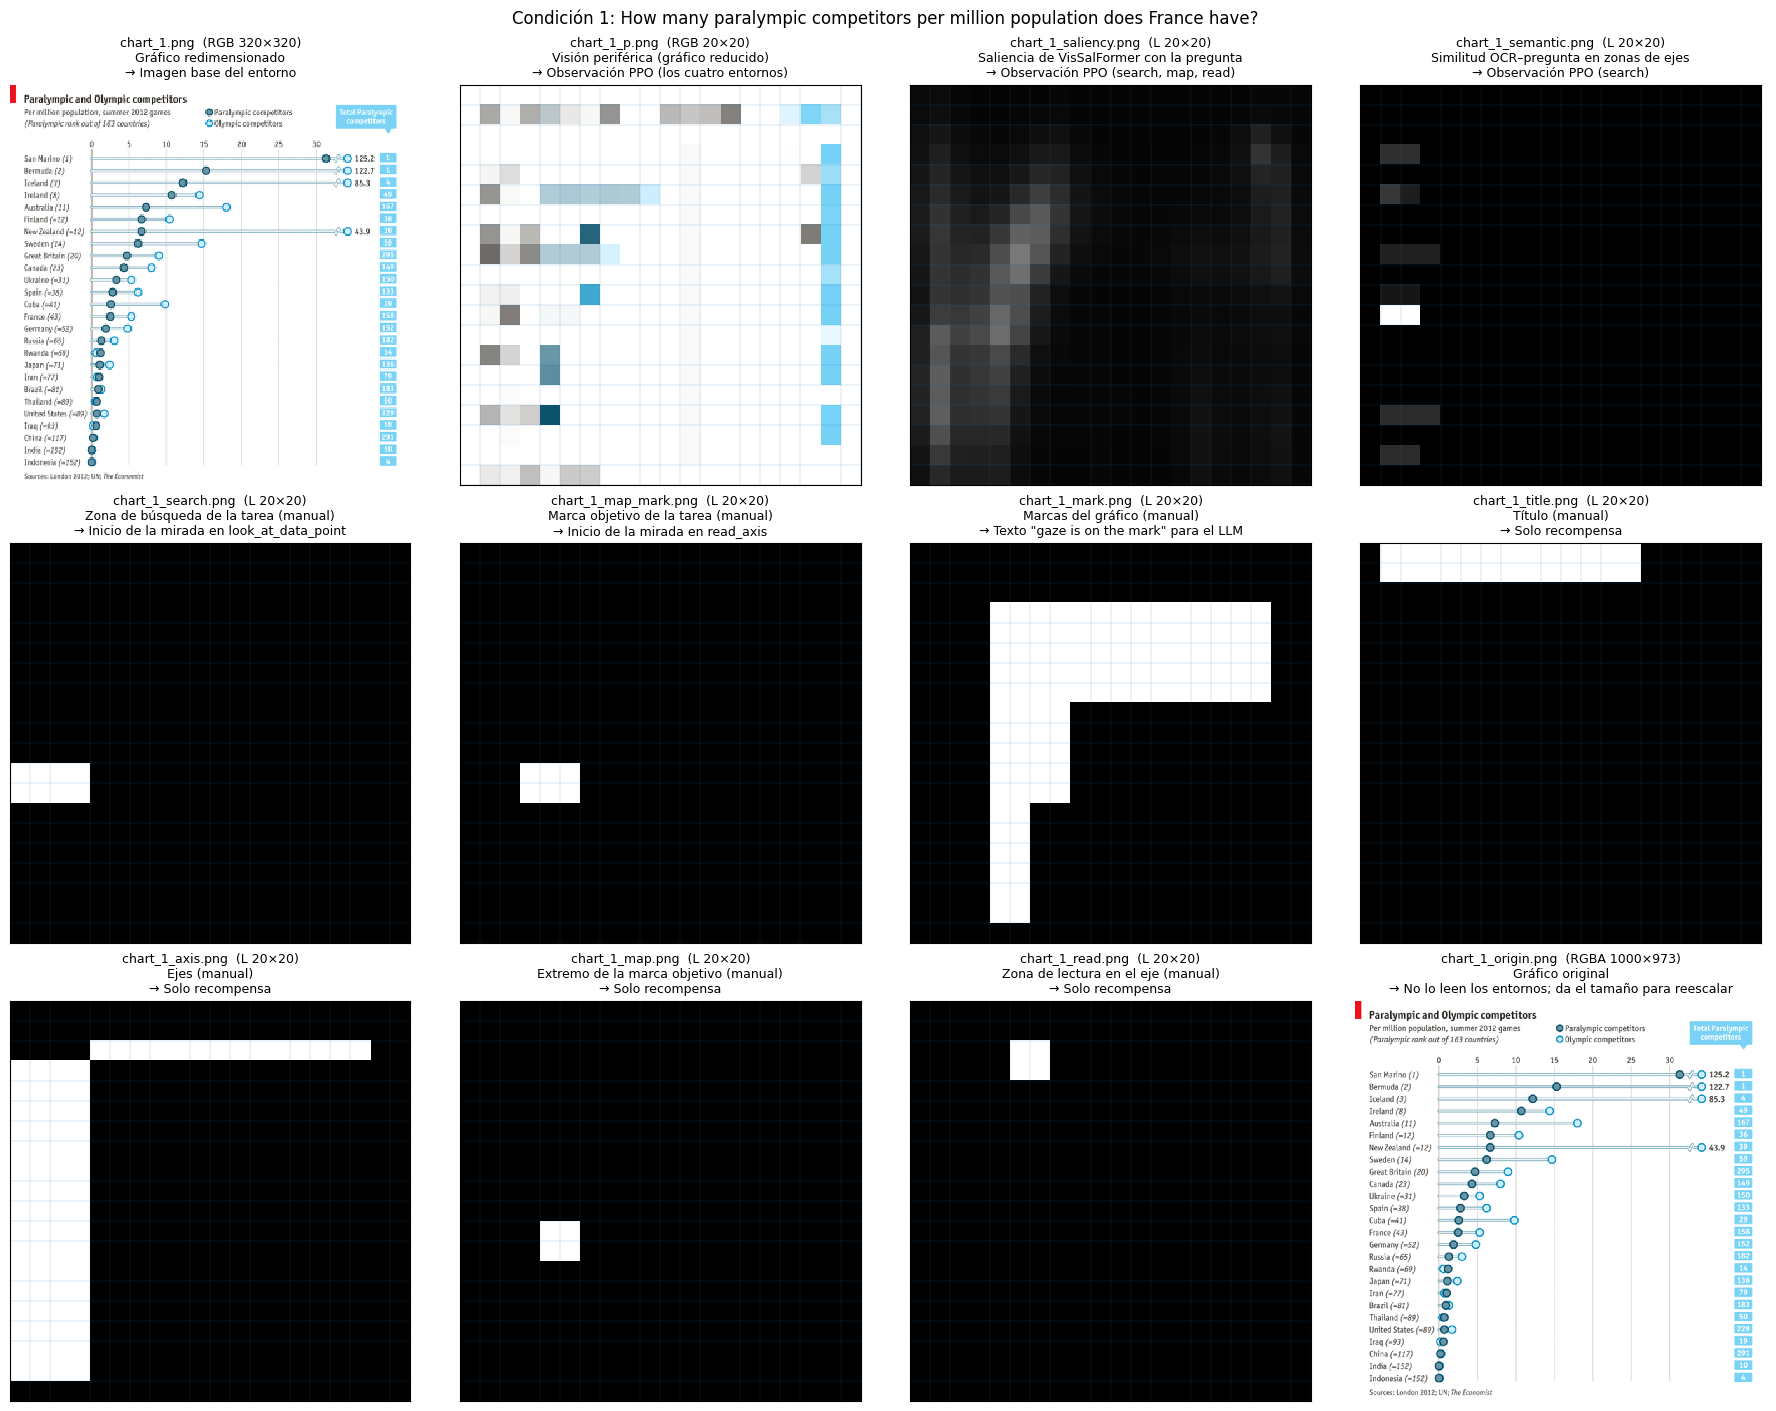

In [22]:
fig, axes = plt.subplots(3, 4, figsize=(18, 14), layout='constrained')
for ax, (suffix, content, use) in zip(axes.flat, INPUT_FILES):
    path = IMAGES / f'chart_{EXAMPLE_ID}{suffix}.png'
    image = Image.open(path)
    ax.imshow(image, cmap='gray' if image.mode == 'L' else None, vmin=0, vmax=255, interpolation='nearest')
    if image.size == (20, 20):
        ax.set_xticks(np.arange(-.5, 20), minor=True)
        ax.set_yticks(np.arange(-.5, 20), minor=True)
        ax.grid(which='minor', color='tab:blue', lw=.3, alpha=.4)
        ax.tick_params(which='both', length=0, labelbottom=False, labelleft=False)
    else:
        ax.axis('off')
    ax.set_title(f"{path.name}  ({image.mode} {image.width}×{image.height})\n{content}\n→ {use}", fontsize=9)
fig.suptitle(f"Condición {EXAMPLE_ID}: {example['question']}")
plt.show()

### Parámetros del modelo

Además de la entrada, la predicción depende de estos parámetros. Casi ninguno aparece en el paper:
salen del código oficial (`llm_policy.py` y los entornos). Nuestra clase solo cambia `MAX_STEPS`, a través del
constructor oficial; el resto queda como en el release.

| Parámetro | Valor en el código | ¿Lo dice el paper? |
|---|---|---|
| LLM de decisión | `gpt-4o` (el gateway de los autores redirigía todo a `gpt4-8k`) | sí, GPT-4o (§3.3) |
| LLM de resumen y respuesta | `gpt-4o-mini` | no |
| Temperatura / semilla | por defecto del servicio, sin semilla | no |
| Máximo de decisiones (`MAX_STEPS`) | **10** en nuestra clase (el release usa 5) | no; se infiere de la Tabla 1 |
| Fijaciones por operación | 5 | no |
| Capacidad de memoria (`MEM_LIMIT`) | 30 | no: solo dice que está "restringida" |
| Olvido | softmax con ρ = 0.1 | sí (§3.3) ✅ |
| Imagen / rejilla | 320 × 320, rejilla 20 × 20 de 16 px, punto al azar dentro de la celda | sí (§3.4) ✅ |
| PPO al predecir | search determinista; map y read estocásticos | no |
| Criterio de parada | ninguno: `answer` no termina, siempre se agotan las decisiones | sí: para cuando la memoria basta (§3.3) ❌ |

**Por qué 10 decisiones.** Cada decisión hace como máximo 5 fijaciones y no hay parada anticipada. Con las 5 decisiones
del release, un recorrido no puede pasar de **25 fijaciones**, pero el paper reporta medias de 48,4 / 48,7 / 46,2
(DE 4,9 / 3,3 / 6,8). Eso encaja con un tope de **10 × 5 = 50**, del que se pierden algunas fijaciones cuando
una decisión falla. Es una inferencia: los autores no publican ese valor.

## 2. Valores del paper (Tabla 1)

*mean* promedia todos los pares humano–predicción de cada tarea. *best* toma, para cada predicción,
el mejor valor frente a los humanos y luego promedia. Sequence Score (SS) es mayor = mejor;
LEV y DTW son menor = mejor.

In [23]:
paper = pd.DataFrame([
    # task, metric, Human, Chartist
    ('retrieve_value', 'Fixations', 88.6, 48.4),
    ('retrieve_value', 'SS mean', 0.486, 0.413), ('retrieve_value', 'SS best', 0.638, 0.472),
    ('retrieve_value', 'LEV mean', 154.7, 151.8), ('retrieve_value', 'LEV best', 121.5, 141.7),
    ('retrieve_value', 'DTW mean', 26018, 28172), ('retrieve_value', 'DTW best', 17692, 23541),
    ('filter', 'Fixations', 89.1, 48.7),
    ('filter', 'SS mean', 0.452, 0.379), ('filter', 'SS best', 0.655, 0.460),
    ('filter', 'LEV mean', 165.8, 155.3), ('filter', 'LEV best', 114.5, 146.4),
    ('filter', 'DTW mean', 23732, 24617), ('filter', 'DTW best', 15238, 19879),
    ('find_extreme', 'Fixations', 91.9, 46.2),
    ('find_extreme', 'SS mean', 0.454, 0.378), ('find_extreme', 'SS best', 0.627, 0.457),
    ('find_extreme', 'LEV mean', 167.3, 151.4), ('find_extreme', 'LEV best', 123.9, 143.9),
    ('find_extreme', 'DTW mean', 27701, 26677), ('find_extreme', 'DTW best', 18626, 22537),
], columns=['task', 'metric', 'Paper human', 'Paper Chartist']).set_index(['task', 'metric'])
paper

Paper human  Paper Chartist
task           metric                                
retrieve_value Fixations       88.600          48.400
               SS mean          0.486           0.413
               SS best          0.638           0.472
               LEV mean       154.700         151.800
               LEV best       121.500         141.700
               DTW mean     26018.000       28172.000
               DTW best     17692.000       23541.000
filter         Fixations       89.100          48.700
               SS mean          0.452           0.379
               SS best          0.655           0.460
               LEV mean       165.800         155.300
               LEV best       114.500         146.400
               DTW mean     23732.000       24617.000
               DTW best     15238.000       19879.000
find_extreme   Fixations       91.900          46.200
               SS mean          0.454           0.378
               SS best          0.627           0.457
               LEV mean       167.300         151.400
               LEV best       123.900         143.900
               DTW mean     27701.000       26677.000
               DTW best     18626.000       22537.000

## 3. Métricas

El paper no publica código de evaluación. Las métricas están en [metrics.py](metrics.py), dentro de esta carpeta.
Siguen las funciones de métricas del grupo de los autores (repositorio de UMSS) y se ajustaron hasta reproducir
la columna *Human* de la Tabla 1:

| Métrica | Cálculo | ¿Reproduce el paper? |
|---|---|---|
| Fijaciones | número de fijaciones por recorrido | sí, exacto |
| LEV | rejilla de 12 × 8 con dos caracteres por fijación (`scanpath_to_string`) y distancia de edición | sí, exacto (mean y best) |
| DTW mean | `fastdtw` compilado (el que se usa por defecto) con distancia euclidiana en píxeles | sí, exacto |
| DTW best | `fastdtw` en Python puro, misma distancia | sí; en *retrieve value* 17 692,5 frente a 17 692 (0,003 %) |
| SS | `nw_matching` sobre una letra por fijación: AOI `title`/`axis`/`mark` de los rótulos oficiales, o `Z` fuera | no: 1–3 % por debajo |

Las dos implementaciones de `fastdtw` dan valores distintos, y cada una reproduce solo su columna. Probablemente
*mean* y *best* salieron de scripts distintos, como en el repositorio de UMSS. Para Sequence Score se probaron
otros conjuntos de AOIs: rótulos de tarea, AOIs de TaskVis, elementos de MASSVIS con leyenda, otras prioridades y
márgenes. Ninguno reproduce las tres tareas a la vez, así que se mantiene el más simple y cercano.

In [24]:
human_paths = {}
for case in cases.itertuples():
    condition = human_fixations[human_fixations.cond_id == f'{case.image}__{TASK_CODE[case.task]}']
    human_paths[case.id] = [g.sort_values('fix_idx')[['x', 'y']].to_numpy(float)
                            for _, g in condition.groupby('participant')]
assert [len(human_paths[i]) for i in cases.id] == cases.n_humans.tolist()
aois = {image: load_aois(OFFICIAL / 'labels' / f'{image}.json') for image in cases.image.unique()}
print('Recorridos humanos:', sum(map(len, human_paths.values())))

Recorridos humanos: 183


## 4. Validación de las métricas: humanos contra humanos

Antes de evaluar el modelo, se reproduce la columna *Human* del paper. Cada humano hace de predicción
frente a todos los de su condición.

En las medias, cada humano **también se compara consigo mismo** (DTW 0, LEV 0, SS 1); sin ese par no salen
los valores publicados. En *best* ese par se excluye. Esto solo afecta a la columna humana: el modelo no tiene
pares consigo mismo.

`Exacto` indica si la diferencia cabe en el redondeo publicado: media unidad del último decimal.

In [25]:
ours_human = evaluate(human_paths, human_paths, cases, aois, self_pairs=True)

validation = paper[['Paper human']].join(ours_human.rename('Our human'))
validation['Diff'] = validation['Our human'] - validation['Paper human']
validation['Rel. diff %'] = 100 * validation['Diff'] / validation['Paper human']
rounding = {'Fixations': .05, 'LEV mean': .05, 'LEV best': .05, 'DTW mean': .5, 'DTW best': .5,
            'SS mean': .0005, 'SS best': .0005}
validation['Exacto'] = validation.Diff.abs() <= validation.index.get_level_values('metric').map(rounding) + 1e-9
validation = validation.loc[TASKS].reindex(METRICS, level='metric')
display(validation.round(4))
print('Métricas exactas:', sorted(set(validation[validation.Exacto].index.get_level_values('metric'))))

Paper human   Our human    Diff  Rel. diff %  Exacto
task           metric                                                         
retrieve_value Fixations       88.600     88.5968 -0.0032      -0.0036    True
               SS mean          0.486      0.4820 -0.0040      -0.8184   False
               SS best          0.638      0.6239 -0.0141      -2.2063   False
               LEV mean       154.700    154.6965 -0.0035      -0.0023    True
               LEV best       121.500    121.4839 -0.0161      -0.0133    True
               DTW mean     26018.000  26017.5336 -0.4664      -0.0018    True
               DTW best     17692.000  17692.5108  0.5108       0.0029   False
filter         Fixations       89.100     89.1167  0.0167       0.0187    True
               SS mean          0.452      0.4384 -0.0136      -3.0179   False
               SS best          0.655      0.6345 -0.0205      -3.1297   False
               LEV mean       165.800    165.7672 -0.0328      -0.0198    True
               LEV best       114.500    114.5000  0.0000       0.0000    True
               DTW mean     23732.000  23731.9632 -0.0368      -0.0002    True
               DTW best     15238.000  15237.7676 -0.2324      -0.0015    True
find_extreme   Fixations       91.900     91.8689 -0.0311      -0.0339    True
               SS mean          0.454      0.4552  0.0012       0.2618   False
               SS best          0.627      0.6137 -0.0133      -2.1239   False
               LEV mean       167.300    167.2846 -0.0154      -0.0092    True
               LEV best       123.900    123.8852 -0.0148      -0.0119    True
               DTW mean     27701.000  27700.6675 -0.3325      -0.0012    True
               DTW best     18626.000  18626.0508  0.0508       0.0003    True

Métricas exactas: ['DTW best', 'DTW mean', 'Fixations', 'LEV best', 'LEV mean']


Fijaciones, LEV y DTW reproducen la columna humana del paper (DTW best en *retrieve value* difiere en 0,5 sobre
17 692, un 0,003 %), así que se aplican igual al modelo.
Sequence Score queda 1–3 % por debajo porque el paper no publica sus AOIs. Diferencias de SS de ese orden
no deben interpretarse.

## 5. Generar los recorridos de nuestro modelo

Se hacen llamadas de pago a OpenAI: `gpt-4o` para decidir, `gpt-4o-mini` para resumir la memoria y responder.
Con 10 decisiones hay unas 20–60 llamadas por recorrido (decisión, resumen de memoria y respuesta final) y 183 recorridos.

- Cada recorrido se guarda en `results/predictions/case_XXX_run_YYY.json` al terminar.
- Su log completo va a `results/logs/case_XXX_run_YYY.json`:
  - cada llamada al LLM: decisión, mensajes enviados, respuesta, modelo servido, tokens y tiempo;
  - el estado final: celdas de mirada, memoria y resumen;
  - lo que imprime el código oficial.
- Si un recorrido falla (por ejemplo, un error de la API), su log parcial se guarda en `results/logs/failed/` con el error
  y la celda se detiene. Al volver a ejecutarla se repite ese recorrido.
- Volver a ejecutar la celda **continúa** donde se quedó; los recorridos ya guardados no se repiten.
- Los puntos se reescalan de 320 × 320 al tamaño original, con truncado a entero como en `log.py`.
- La clave API se toma de `OPENAI_API_KEY` o se pide con entrada oculta. No se guarda en ningún sitio.

Para una prueba barata, poner `RUNS_PER_CASE = 1` y `CASE_IDS = [1, 16, 30]` (una condición por tarea).

In [26]:
RUN_INFERENCE = True
RUNS_PER_CASE = 1
CASE_IDS = [1]

if RUN_INFERENCE:
    import os
    from datetime import datetime, timezone
    from getpass import getpass
    from models import load_predictor

    predictor = load_predictor('chartist', api_key=os.environ.get('OPENAI_API_KEY') or getpass('OpenAI API key: '))
    PREDICTIONS.mkdir(parents=True, exist_ok=True)
    (LOGS / 'failed').mkdir(parents=True, exist_ok=True)
    for case in cases.itertuples():
        if CASE_IDS is not None and case.id not in CASE_IDS:
            continue
        for run in range(RUNS_PER_CASE or case.n_humans):
            name = f'case_{case.id:03d}_run_{run:03d}'
            output = PREDICTIONS / f'{name}.json'
            if output.exists():
                continue
            started = datetime.now(timezone.utc).isoformat(timespec='seconds')
            header = dict(case_id=case.id, task=case.task, run=run, question=meta_by_id[case.id]['question'],
                          started_at=started)
            try:
                prediction = predictor.predict(meta_by_id[case.id], meta_json=OFFICIAL / 'meta.json',
                                               folder=OFFICIAL / 'images')
            except BaseException as error:
                failed = dict(header, status='failed', error=repr(error), **predictor.last_log)
                (LOGS / 'failed' / f"{name}_{started.replace(':', '')}.json").write_text(
                    json.dumps(failed, indent=2, default=str))
                raise
            (LOGS / f'{name}.json').write_text(json.dumps(
                dict(header, status='completed', answer=prediction['answer'], actions=prediction['actions'],
                     points_320=prediction['points'], **prediction['log']), indent=2, default=str))
            points = [[int(x * case.width / 320), int(y * case.height / 320)] for x, y in prediction['points']]
            output.write_text(json.dumps(dict(case_id=case.id, task=case.task, run=run, points=points,
                                              answer=prediction['answer'], actions=prediction['actions']),
                                         indent=2, default=str))
            print(f'caso {case.id} ({case.task}) recorrido {run}: {len(points)} fijaciones, '
                  f"{len(prediction['log']['llm_calls'])} llamadas, {prediction['log']['seconds']:.0f} s")

caso 1 (retrieve_value) recorrido 0: 10 fijaciones, 45 llamadas, 55 s


### Revisar el log de un recorrido

Resumen de las llamadas al LLM de un recorrido guardado. Para ver los mensajes completos, abrir el JSON en `results/logs/`.

In [27]:
LOG_CASE, LOG_RUN = 1, 0
log_path = LOGS / f'case_{LOG_CASE:03d}_run_{LOG_RUN:03d}.json'
if not log_path.exists():
    print('Todavía no existe', log_path.relative_to(EXPERIMENT))
else:
    run_log = json.loads(log_path.read_text())
    print(f"Caso {run_log['case_id']} ({run_log['task']}), recorrido {run_log['run']}: {run_log['status']}, "
          f"{run_log['steps']} pasos, {len(run_log['points_320'])} fijaciones, {run_log['seconds']:.0f} s")
    print('Respuesta:', run_log['answer'])
    calls = pd.DataFrame([dict(decision=c['decision'], requested=c['request']['model'], served=c.get('served_model'),
                               tokens=(c.get('usage') or {}).get('total_tokens'), seconds=round(c.get('seconds', 0), 1),
                               response=(c.get('response') or c.get('error', ''))[:120]) for c in run_log['llm_calls']])
    display(calls)
    if run_log['stdout']:
        print('Salida del código oficial:\n' + run_log['stdout'])

Caso 1 (retrieve_value), recorrido 0: completed, 11 pasos, 10 fijaciones, 55 s
Respuesta: {'answer': '43', 'reason': "I gathered the information from the chart that states 'France43' in my memory, which indicates that France has 43 paralympic competitors per million population."}


,decision,requested,served,tokens,seconds,response
0,1,gpt-4o,gpt-4o-2024-08-06,634,2.9,"{""function"": ""search_text"", ""parameter"": """", ""reason"": ""I need to find the location of France in the chart to determine"
1,1,gpt-4o-mini,gpt-4o-mini-2024-07-18,630,1.1,"{""function"": ""explore"", ""parameter"": """", ""reason"": ""I have no information about the chart, so I need to explore it to un"
2,2,gpt-4o,gpt-4o-2024-08-06,848,1.3,"{""function"": ""explore"", ""parameter"": """", ""reason"": ""I need to gather more information about the chart since I have not y"
3,2,gpt-4o-mini,gpt-4o-mini-2024-07-18,849,1.4,"{""function"": ""search_text"", ""parameter"": """", ""reason"": ""I need to search for the label or value associated with France t"
4,3,gpt-4o,gpt-4o-2024-08-06,1042,1.3,"{""function"": ""answer"", ""parameter"": """", ""reason"": ""I have already gathered the information that France has 43 Paralympic"
5,3,gpt-4o,gpt-4o-2024-08-06,1035,1.3,"{""function"": ""answer"", ""parameter"": """", ""reason"": ""I already found the number of Paralympic competitors per million popu"
6,3,gpt-4o,gpt-4o-2024-08-06,1026,1.3,"{""function"": ""answer"", ""parameter"": """", ""reason"": ""I have found the information that France has 43 Paralympic competitor"
7,3,gpt-4o,gpt-4o-2024-08-06,1026,1.2,"{""function"": ""answer"", ""parameter"": """", ""reason"": ""I have found in my memory that France has 43 Paralympic competitors p"
8,3,gpt-4o,gpt-4o-2024-08-06,1028,1.6,"{""function"": ""answer"", ""parameter"": """", ""reason"": ""I have found the information that France has 43 Paralympic competitor"
9,4,gpt-4o,gpt-4o-2024-08-06,1257,1.0,"{""function"": ""answer"", ""parameter"": """", ""reason"": ""I have already found from my memory that France has 43 Paralympic com"


## 6. Nuestro modelo frente al paper

In [28]:
records = [json.loads(p.read_text()) for p in sorted(PREDICTIONS.glob('case_*_run_*.json'))]
predictions = pd.DataFrame(records, columns=['case_id', 'task', 'run', 'points', 'answer', 'actions'])

coverage = cases.set_index('id')[['task', 'n_humans']].rename(columns={'n_humans': 'Expected'})
coverage['Saved'] = predictions.groupby('case_id').size().reindex(coverage.index, fill_value=0)
display(coverage)
print(f'Recorridos guardados: {len(predictions)} de {coverage.Expected.sum()}')

,task,Expected,Saved
id,,,
1,retrieve_value,15,1
6,filter,15,0
9,find_extreme,15,0
11,retrieve_value,15,0
16,filter,16,0
19,find_extreme,15,0
21,retrieve_value,16,0
25,filter,15,0
30,find_extreme,16,0


Recorridos guardados: 1 de 183


In [29]:
if predictions.empty:
    print('Todavía no hay recorridos propios: activar RUN_INFERENCE en la sección 5.')
else:
    model_paths = {case_id: [np.asarray(points, float) for points in group.points]
                   for case_id, group in predictions.groupby('case_id')}
    ours = evaluate(model_paths, human_paths, cases, aois)
    model_counts = predictions.set_index('task').points.map(len)

    comparison = paper.join(ours.rename('Our Chartist'))
    comparison['Our − paper'] = comparison['Our Chartist'] - comparison['Paper Chartist']
    comparison['Runs'] = predictions.groupby('task').size().reindex(comparison.index.get_level_values('task')).values
    display(comparison.loc[TASKS].reindex(METRICS, level='metric').round(3))

    sd = pd.DataFrame({'Paper (SD)': pd.Series({'retrieve_value': 4.9, 'filter': 3.3, 'find_extreme': 6.8}),
                       'Our SD': model_counts.groupby('task').std(),
                       'Our min': model_counts.groupby('task').min(),
                       'Our max': model_counts.groupby('task').max(),
                       'Empty runs': (model_counts == 0).groupby('task').sum()}).loc[TASKS]
    display(sd.round(1))

Paper human  Paper Chartist  Our Chartist  \
task           metric                                                 
retrieve_value Fixations       88.600          48.400        10.000   
               SS mean          0.486           0.413         0.089   
               SS best          0.638           0.472         0.200   
               LEV mean       154.700         151.800       248.800   
               LEV best       121.500         141.700        18.000   
               DTW mean     26018.000       28172.000     45164.380   
               DTW best     17692.000       23541.000      2958.045   
filter         Fixations       89.100          48.700           NaN   
               SS mean          0.452           0.379           NaN   
               SS best          0.655           0.460           NaN   
               LEV mean       165.800         155.300           NaN   
               LEV best       114.500         146.400           NaN   
               DTW mean     23732.000       24617.000           NaN   
               DTW best     15238.000       19879.000           NaN   
find_extreme   Fixations       91.900          46.200           NaN   
               SS mean          0.454           0.378           NaN   
               SS best          0.627           0.457           NaN   
               LEV mean       167.300         151.400           NaN   
               LEV best       123.900         143.900           NaN   
               DTW mean     27701.000       26677.000           NaN   
               DTW best     18626.000       22537.000           NaN   

                          Our − paper  Runs  
task           metric                        
retrieve_value Fixations      -38.400   1.0  
               SS mean         -0.324   1.0  
               SS best         -0.272   1.0  
               LEV mean        97.000   1.0  
               LEV best      -123.700   1.0  
               DTW mean     16992.380   1.0  
               DTW best    -20582.955   1.0  
filter         Fixations          NaN   NaN  
               SS mean            NaN   NaN  
               SS best            NaN   NaN  
               LEV mean           NaN   NaN  
               LEV best           NaN   NaN  
               DTW mean           NaN   NaN  
               DTW best           NaN   NaN  
find_extreme   Fixations          NaN   NaN  
               SS mean            NaN   NaN  
               SS best            NaN   NaN  
               LEV mean           NaN   NaN  
               LEV best           NaN   NaN  
               DTW mean           NaN   NaN  
               DTW best           NaN   NaN

,Paper (SD),Our SD,Our min,Our max,Empty runs
retrieve_value,4.9,NaN,10.0,10.0,0.0
filter,3.3,NaN,NaN,NaN,NaN
find_extreme,6.8,NaN,NaN,NaN,NaN


### Ejemplo visual

Un humano y un recorrido nuestro de la misma condición, sobre el gráfico original.

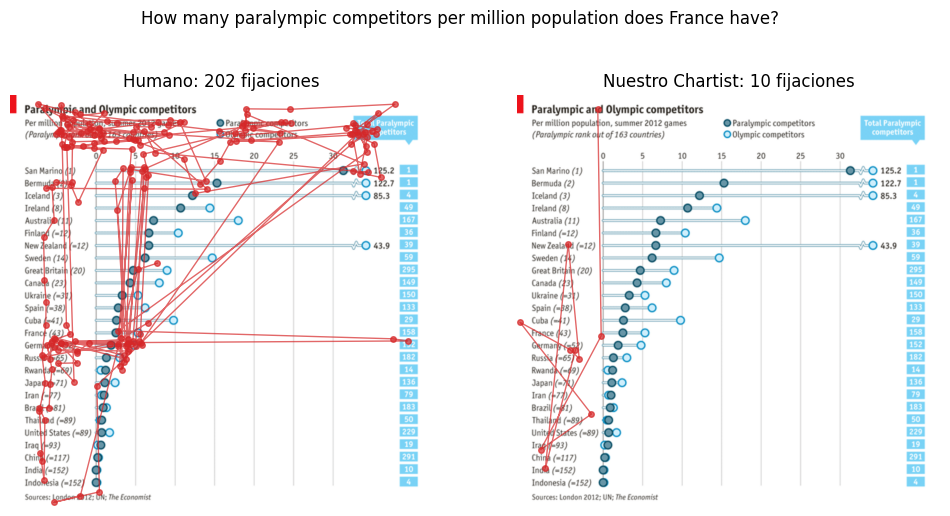

In [30]:
if not predictions.empty:
    row = predictions.iloc[0]
    case = cases.set_index('id').loc[row.case_id]
    image = Image.open(OFFICIAL / 'labels' / f'{case.image}.png')
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    for ax, (title, path) in zip(axes, [('Humano', human_paths[row.case_id][0]),
                                         ('Nuestro Chartist', np.asarray(row.points, float))]):
        ax.imshow(image)
        if len(path):
            ax.plot(path[:, 0], path[:, 1], '-o', ms=4, lw=1, alpha=.7, color='tab:red')
        ax.set_title(f'{title}: {len(path)} fijaciones')
        ax.axis('off')
    fig.suptitle(case.question)
    plt.show()

## Diferencias conocidas con el paper

- **Número de decisiones.** Usamos `MAX_STEPS = 10` en lugar de las 5 del release, inferido de las ~48 fijaciones
  del paper (tope de 50). Si el valor real fuera otro, cambiarían la longitud y todas las métricas de secuencia.
- **Parada.** El controlador publicado nunca termina antes de agotar las decisiones, porque `answer` no tiene rama
  propia. Lo conservamos tal cual.
- **LLM.** El código pide `gpt-4o`/`gpt-4o-mini`, pero el gateway de los autores enviaba todo a un despliegue
  `gpt4-8k`. No se sabe qué versión usaron.
- **Defectos del release que se conservan:** el prompt siempre dice "a scatterplot", y el resumen de memoria
  reenvía los mensajes de decisión.
- **Sequence Score.** Las AOIs del paper no están publicadas. Usamos `title`/`axis`/`mark` de los rótulos oficiales,
  que quedan 1–3 % por debajo en la columna humana. El resto de métricas reproduce el paper exactamente.
- **Aleatoriedad.** Las políticas map/read son estocásticas y no hay semilla, igual que en `log.py`.